# Usage | 3. Data imports for city definition
This notebook explains how custom data sets can be imported into FixBikeNet to define custom city properties, adapting to a local situation and growing more realistically.

**Parameters covered**: `import_files['street_network'], import_files['city_boundary']`  
**Modules covered**: `bnl.osm`

We start every Usage notebook with the standard way of importing FixBikeNet:

In [1]:
import fixbikenet as fbn

## Save and import street network

Here we work with Frederiksberg municipality, Denmark. When running FixBikeNet, it uses OSMnx to fetch street network data from [OSM](https://www.openstreetmap.org/) to be used as the combined street and bicycle network (`carpbi`, standing for car+protected bicyclye infrastructure - the network on which cars and bicycles move) on which to identify gaps for cycling. OSMnx has data caching implemented, so when running it multiple times on the same city, it will load the cached json data. Unfortunately, loading json is slow. To speed up this process, we can first download and save the street network locally, under `Frederiksberg_carpbi_network.gpkg`, so we can load that file fast into FixBikeNet whenever we will use it (because gpkg files are loaded fast).

FixBikeNet downloads as its carpbi network a combination of both driveable and bikeable infrastructure elements. These elements are defined in the constant `CARPBI_NETWORK_CUSTOM_FILTER` of the `osm` module of BikeNetLib - which is BikeNetKit's core utilities package. If you want to recreate this in your local import, you can run the following code:

In [2]:
import osmnx as ox
import bikenetlib as bnl

g = ox.graph_from_place("Frederiksberg municipality", simplify=False, retain_all=True, custom_filter = bnl.osm.CARPBI_NETWORK_CUSTOM_FILTER)
ox.io.save_graph_geopackage(g, "Frederiksberg_carpbi_network.gpkg")

Now, we can use this local street network file with the `"street_network"` key inside the `import_files` dictionary parameter:

In [4]:
gaps_ordered = fbn.fixbikenet(
    "Frederiksberg municipality",
    import_files={"street_network":"Frederiksberg_carpbi_network.gpkg"}
)

RUNNING FIXBIKENET FOR CITY: Frederiksberg municipality
----------------------------------------------╮


Exporting data         : 100%|████████████████| 1/1 [00:00<00:00, 10.62file/s]


----------------------------------------------╯
Data exported to ./results/
----------------------------------------------
FINISHED IN 0:01:18


This way, the street network file can also come from any other data provider than OSM, given that the data is in the same format, or it can be modified.

## Import city boundary

When FixBikeNet runs, it automatically finds the city boundary on OSM via OSMnx's `graph_from_place()` function from the given `city_query`. However, sometimes the desired city boundary does not exist on OSM. In Copenhagen, for example, OSMnx returns a multipolygon consisting of several polygons -two big and some small islands-, where also one of the big polygons has a hole inside (which is Frederiksberg municipality). This is demonstrated using OSMnx's `geocode_to_gdf()` function which downloads the city boundary from a query:

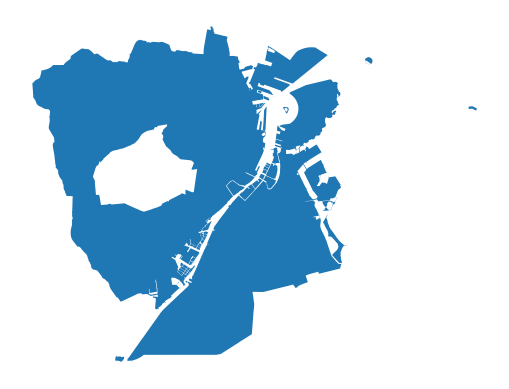

In [5]:
copenhagen_boundary = ox.geocoder.geocode_to_gdf("copenhagen municipality")
ax = copenhagen_boundary.plot()
ax.set_axis_off()

This shape is suboptimal, as it does not cover bridges nor Frederiksberg. Because of such cases, and also to provide a completely flexible framework allowing to focus on places not encoded in OSM like neighborhoods, GrowBikeNet provides a city boundary import option via the `import_files['city_boundary']` parameter. This boundary can be a gpkg, geojson, or a shape (shp) file. One is provided in FixBikeNet's [`tests` folder](https://github.com/BikeNetKit/FixBikeNet/tree/main/tests/test_data):

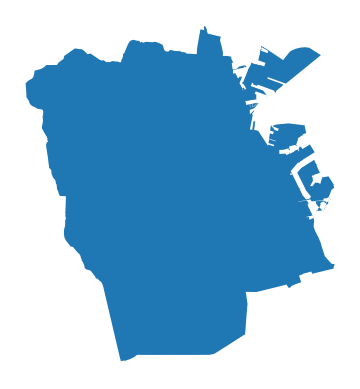

In [7]:
import geopandas as gpd

boundary_path = '../../tests/test_data/copenhagen_boundary.geojson'
copenhagen_boundary_fixed = gpd.read_file(boundary_path)
ax = copenhagen_boundary_fixed.plot()
ax.set_axis_off()

In [9]:
gaps_ordered = fbn.fixbikenet(
    "Copenhagen",
    import_files = {'city_boundary': boundary_path}
)

RUNNING FIXBIKENET FOR CITY: Copenhagen
----------------------------------------------╮


Exporting data         : 100%|████████████████| 1/1 [00:00<00:00,  4.38file/s]

----------------------------------------------╯
Data exported to ./results/
----------------------------------------------
FINISHED IN 0:02:20


We can see how the whole city is now covered, including Frederiksberg:

In [10]:
gaps_ordered.explore(
    tiles="https://tiles.stadiamaps.com/tiles/alidade_smooth/{z}/{x}/{y}{r}.png", 
    attr="(C) Stadia Maps (C) OpenMapTiles (C) OpenStreetMap contributors",
    style_kwds={"weight": 3, "color": "#096a51"},
)